In [1]:
import pandas as pd

# Load data
solar_data = pd.read_csv('solar_data_merged.csv')

# Quick check
print(solar_data.shape)       # Number of rows & columns
print(solar_data.columns)     # List all columns
solar_data.head()

(5117, 16)
Index(['location_name', 'country', 'latitude', 'longitude', 'date', 'year',
       'month', 'day', 'day_of_week', 'ghi_kwh_m2', 'clear_sky_ghi_kwh_m2',
       'temperature_c', 'wind_speed_ms', 'relative_humidity_pct',
       'estimated_daily_generation_kwh', 'data_quality'],
      dtype='object')


,location_name,country,latitude,longitude,date,year,month,day,day_of_week,ghi_kwh_m2,clear_sky_ghi_kwh_m2,temperature_c,wind_speed_ms,relative_humidity_pct,estimated_daily_generation_kwh,data_quality
0,Accra_Ghana,Ghana,5.604,-0.187,2024-02-09,2024.0,2.0,9.0,Friday,5.0825,5.1367,28.26,3.36,82.28,8.64025,good
1,Accra_Ghana,Ghana,5.604,-0.187,2024-02-10,2024.0,2.0,10.0,Saturday,5.1946,5.2385,28.46,3.39,83.20,8.83082,good
2,Accra_Ghana,Ghana,5.604,-0.187,2024-02-11,2024.0,2.0,11.0,Sunday,5.3086,5.3803,28.63,3.32,83.94,9.02462,good
3,Accra_Ghana,Ghana,5.604,-0.187,2024-02-12,2024.0,2.0,12.0,Monday,5.1290,5.2661,28.31,3.11,86.70,8.71930,good
4,Accra_Ghana,Ghana,5.604,-0.187,2024-02-13,2024.0,2.0,13.0,Tuesday,5.1648,5.4192,28.97,3.77,85.19,8.78016,good


In [2]:
# Replace -999 or missing data with NaN (if not already done)
solar_data.replace(-999, pd.NA, inplace=True)

# Keep only rows where data_quality is 'good'
solar_data_clean = solar_data[solar_data['data_quality'] == 'good'].copy()

# Optional: drop rows where GHI is missing
solar_data_clean = solar_data_clean.dropna(subset=['ghi_kwh_m2'])

# Reset index
solar_data_clean.reset_index(drop=True, inplace=True)

print(f"Cleaned data has {solar_data_clean.shape[0]} rows")


Cleaned data has 5075 rows


In [3]:
# Define mapping
region_map = {
    'Accra_Ghana': 'West Africa',
    'Lagos_Nigeria': 'West Africa',
    'Dar_es_Salaam_Tanzania': 'East Africa',
    'Nairobi_Kenya': 'East Africa',
    'Kampala_Uganda': 'East Africa',
    'Kigali_Rwanda': 'East Africa',
    'Johannesburg_SA': 'Southern Africa'
}

# Add a region column
solar_data_clean['region'] = solar_data_clean['location_name'].map(region_map)

# Quick check
solar_data_clean[['location_name', 'region']].drop_duplicates()


,location_name,region
0,Accra_Ghana,West Africa
725,Dar_es_Salaam_Tanzania,East Africa
1450,Johannesburg_SA,Southern Africa
2175,Kampala_Uganda,East Africa
2900,Kigali_Rwanda,East Africa
3625,Lagos_Nigeria,West Africa
4350,Nairobi_Kenya,East Africa


In [4]:
city_stats = solar_data_clean.groupby('location_name')['ghi_kwh_m2'].agg(
    mean_ghi='mean',
    min_ghi='min',
    max_ghi='max',
    std_ghi='std'
).reset_index()

print(city_stats)


            location_name  mean_ghi  min_ghi  max_ghi   std_ghi
0             Accra_Ghana  4.768716   1.2290   6.8717  0.943308
1  Dar_es_Salaam_Tanzania  5.663373   0.7788   7.4518  1.314643
2         Johannesburg_SA  5.316979   0.9050   9.3840  1.548795
3          Kampala_Uganda  5.114424   1.7338   7.4520  1.008357
4           Kigali_Rwanda  4.877396   0.6619   7.5204  1.081640
5           Lagos_Nigeria  4.586861   0.2650   6.6574  1.136691
6           Nairobi_Kenya  5.777731   1.4736   8.0964  1.181289


In [5]:
region_stats = solar_data_clean.groupby('region')['ghi_kwh_m2'].agg(
    mean_ghi='mean',
    median_ghi='median',
    std_ghi='std',
    min_ghi='min',
    max_ghi='max'
).reset_index()

print(region_stats)

            region  mean_ghi  median_ghi   std_ghi  min_ghi  max_ghi
0      East Africa  5.358231     5.43060  1.210877   0.6619   8.0964
1  Southern Africa  5.316979     5.11560  1.548795   0.9050   9.3840
2      West Africa  4.677789     4.93225  1.048079   0.2650   6.8717


In [6]:
top_cities = city_stats.sort_values(by='mean_ghi', ascending=False).reset_index(drop=True)
top_cities['rank'] = top_cities.index + 1

print("Top solar cities in SSA:")
print(top_cities[['rank', 'location_name', 'mean_ghi']])


Top solar cities in SSA:
   rank           location_name  mean_ghi
0     1           Nairobi_Kenya  5.777731
1     2  Dar_es_Salaam_Tanzania  5.663373
2     3         Johannesburg_SA  5.316979
3     4          Kampala_Uganda  5.114424
4     5           Kigali_Rwanda  4.877396
5     6             Accra_Ghana  4.768716
6     7           Lagos_Nigeria  4.586861


In [7]:
# Save summary tables
city_stats.to_csv('city_solar_summary.csv', index=False)
region_stats.to_csv('region_solar_summary.csv', index=False)
top_cities.to_csv('top_solar_cities.csv', index=False)

print("CSV files ready for Power BI dashboards.")


CSV files ready for Power BI dashboards.


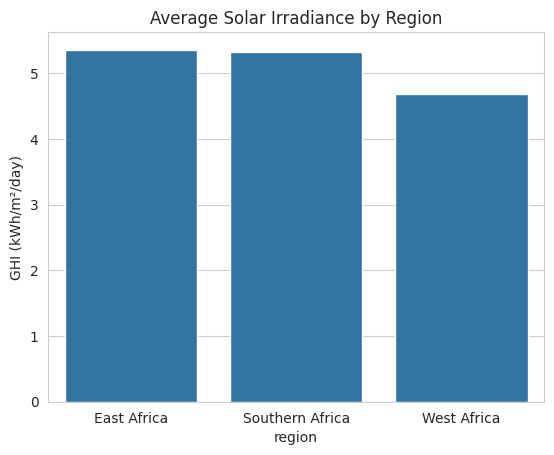

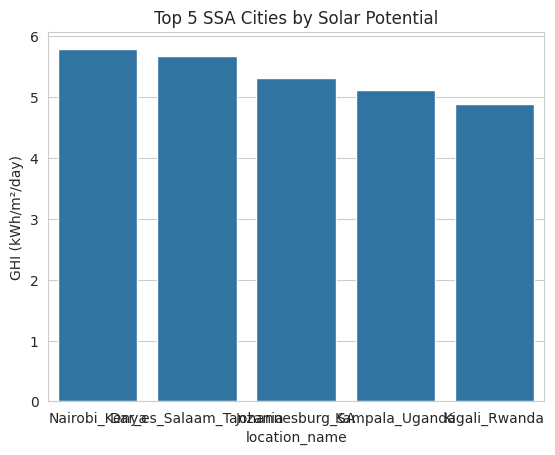

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# Mean GHI by region
sns.barplot(data=region_stats, x='region', y='mean_ghi')
plt.title('Average Solar Irradiance by Region')
plt.ylabel('GHI (kWh/m²/day)')
plt.show()

# Top cities
sns.barplot(data=top_cities.head(5), x='location_name', y='mean_ghi')
plt.title('Top 5 SSA Cities by Solar Potential')
plt.ylabel('GHI (kWh/m²/day)')
plt.show()

